# Lab 9 - Gyroscope parameters (variant 57)

Option A: open-loop in-place rotation (`sin`, `rect`), static run first.
Change `RUN` below to `'real'` once `log/real_gyro_57.csv` is copied from the robot. Nothing else needs editing.

**Log columns:** `phase, t_ms, t_us, [gz_raw,] gz_cal, encL, encR`. Phase 0 = static, 1 = sin, 2 = rect, 3 = rest.
`gz_cal` is `read()[2]` in mdeg/s. `gz_raw` exists only if the JS program was used (`gyro_real.js`).

In [21]:
import numpy as np
import matplotlib.pyplot as plt

RUN = 'sim'                      # 'sim' or 'real'
SLIP_DEG = None                  # real run only: angle left on the protractor after returning to the tape mark
ENC_SIGN = 1                     # -1 if the encoders count backwards (check the sign test below)

# robot geometry, same values as the programs use. The scale factor s depends on r/W (see section 6):
# a 10% error in r gives a 10 % error in s. Use your measured r, W.
GEOM = {'sim': dict(r=0.028, W=0.154), 'real': dict(r=0.042, W=0.194)}
r, W = GEOM[RUN]['r'], GEOM[RUN]['W']

plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'axes.spines.top': False, 'axes.spines.right': False})

## Load the log

In [22]:
data = np.loadtxt(f'log/{RUN}_gyro_57.csv', delimiter=',')
n_rows = len(data)
# the program loop is faster than the gyro: the same gyro sample can be logged twice -> keep one (same t_us)
data = data[np.concatenate([[True], np.diff(data[:, 2]) != 0])]
print(f'{n_rows - len(data)} of {n_rows} rows were repeats of the previous gyro sample and were dropped')
has_raw = data.shape[1] == 7
if has_raw:
    phase, t_ms, t_us, gz_raw, gz_cal, encL, encR = data.T
else:
    phase, t_ms, t_us, gz_cal, encL, encR = data.T
    gz_raw = None

# time axis. The README calls t_us microseconds; compare it with the program clock t_ms to get the real unit
# (on the TRIK it is 0.256 ms per unit).
unit_ms = np.polyfit(t_us - t_us[0], t_ms - t_ms[0], 1)[0]
use_us = np.corrcoef(t_us, t_ms)[0, 1] > 0.9999
t = (t_us - t_us[0]) * unit_ms / 1000 if use_us else (t_ms - t_ms[0]) / 1000
print(f'one unit of t_us = {unit_ms:.4f} ms; time axis from {"gyro timestamps" if use_us else "program clock (t_ms)"}')
print(f'{len(t)} samples, {t[-1]:.1f} s, mean dt = {np.mean(np.diff(t))*1000:.1f} ms ({1/np.mean(np.diff(t)):.0f} samples/s)')

w_signed = gz_cal / 1000                           # deg/s, sign as the sensor reports it
phi_L = ENC_SIGN * (encL - encL[0])                # encoder angles, deg (check the unit: degrees, not ticks)
phi_R = ENC_SIGN * (encR - encR[0])
theta_enc = np.degrees(r / W * np.radians(phi_R - phi_L))   # heading from the wheels, deg
static, sin_, rect_, rest_ = [phase == k for k in range(4)]
rot = sin_ | rect_
fs = 1 / np.mean(np.diff(t))

# encoder rate: central difference over +-0.1 s (robust to repeated timestamps)
K = max(2, int(0.1 * fs))
idx = np.arange(len(t))
lo, hi = np.clip(idx - K, 0, len(t) - 1), np.clip(idx + K, 0, len(t) - 1)
enc_rate = (theta_enc[hi] - theta_enc[lo]) / (t[hi] - t[lo])

# SIGN TEST: encoders count CCW as positive. Does the gyro agree?
corr = np.corrcoef(w_signed[rot], enc_rate[rot])[0, 1]
GYRO_SIGN = 1 if corr > 0 else -1
direction = 'CCW' if corr > 0 else 'CW'
print(f'correlation gyro vs encoder rate = {corr:.3f} -> the gyro reports positive for {direction} rotation')
w = GYRO_SIGN * w_signed                           # from here on: positive = CCW, same as the encoders

12770 of 25540 rows were repeats of the previous gyro sample and were dropped
one unit of t_us = 0.2560 ms; time axis from gyro timestamps
12770 samples, 255.4 s, mean dt = 20.0 ms (50 samples/s)
correlation gyro vs encoder rate = -0.989 -> the gyro reports positive for CW rotation


## 1. Offset (bias) b0

Mean of the first 30 s of the static log, plus the standard error `sigma/sqrt(N)`. Then b0 from the first 1, 2, 5, 10, 20, 30 s.

b0 = 0.0000 deg/s  (standard error 0.00000, N = 1501)


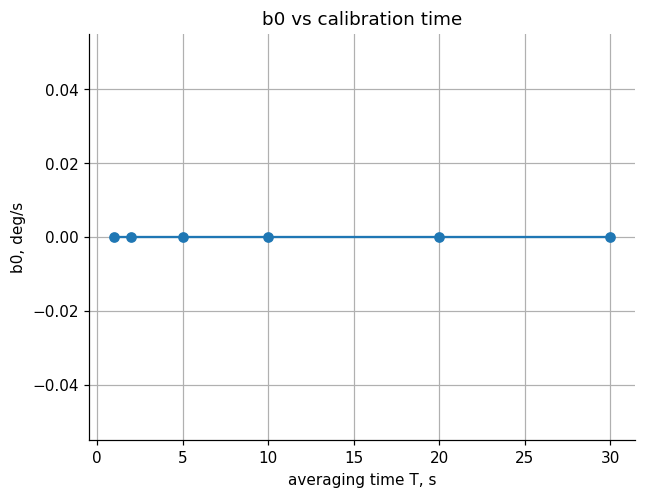

In [23]:
ts, ws = t[static], w[static]
def b0_first(T): return ws[ts - ts[0] < T].mean()

T30 = ws[ts-ts[0]<30]
b0 = T30.mean()
b0_se = T30.std(ddof=1) / np.sqrt(len(T30))
print(f'b0 = {b0:.4f} deg/s  (standard error {b0_se:.5f}, N = {len(T30)})')

Ts = [1, 2, 5, 10, 20, 30]
b0_T = [b0_first(T) for T in Ts]
plt.plot(Ts, b0_T, 'o-'); plt.xlabel('averaging time T, s'); plt.ylabel('b0, deg/s'); plt.title('b0 vs calibration time')
plt.show()

### Own calibration method: `calibrate_gyro`

The robot stands still, so the mean of the readings is the offset. A median-based version ignores spikes:
1. take the first `T_cal` seconds of the static log,
2. throw away samples further than 3 x MAD-sigma from the median (spikes),
3. average what is left.

`T_cal` is where the curve above flattens (see the printed values below).

In [24]:
def calibrate_gyro(t_static, w_static, T_cal=10):
    x = w_static[t_static - t_static[0] < T_cal]
    med = np.median(x)
    sigma = 1.4826 * np.median(np.abs(x - med))        # robust std estimate
    keep = np.abs(x - med) <= 3 * sigma if sigma > 0 else np.ones_like(x, bool)
    return x[keep].mean()

T_CAL = 10
b0_own = calibrate_gyro(ts, ws, T_CAL)
print(f'calibrate_gyro(T_cal={T_CAL} s) = {b0_own:.4f} deg/s   (30 s mean: {b0:.4f})')
print('b0(T) =', dict(zip(Ts, np.round(b0_T, 4))))

# The offset moves during the 3 min (section 2), so on the robot the calibration should be done right before the run:
# the LAST T_CAL seconds of the static phase. This value is used for the rotation run below.
last = ts - ts[0] >= (ts[-1] - ts[0]) - T_CAL
b0_run = calibrate_gyro(ts[last], ws[last], T_CAL)
print(f'calibrate_gyro on the last {T_CAL} s before the run = {b0_run:.4f} deg/s')

calibrate_gyro(T_cal=10 s) = 0.0000 deg/s   (30 s mean: 0.0000)
b0(T) = {1: 0.0, 2: 0.0, 5: 0.0, 10: 0.0, 20: 0.0, 30: 0.0}
calibrate_gyro on the last 10 s before the run = 0.0000 deg/s


## 2. Bias drift d

The full static log is split into 30 s windows. The line through the window means has slope `d`.
The rate is integrated with the trapezoid rule on the real timestamps.

window means, deg/s: [0. 0. 0. 0. 0.]
d = 0.00000 deg/s per min
(a) uncorrected heading drift = 0.000 deg/min   (b0*60 = 0.000)
(b) heading error after 1 min with b0 removed: -0.000 deg
(b) heading error after 2 min with b0 removed: -0.000 deg
(b) heading error after 3 min with b0 removed: -0.000 deg


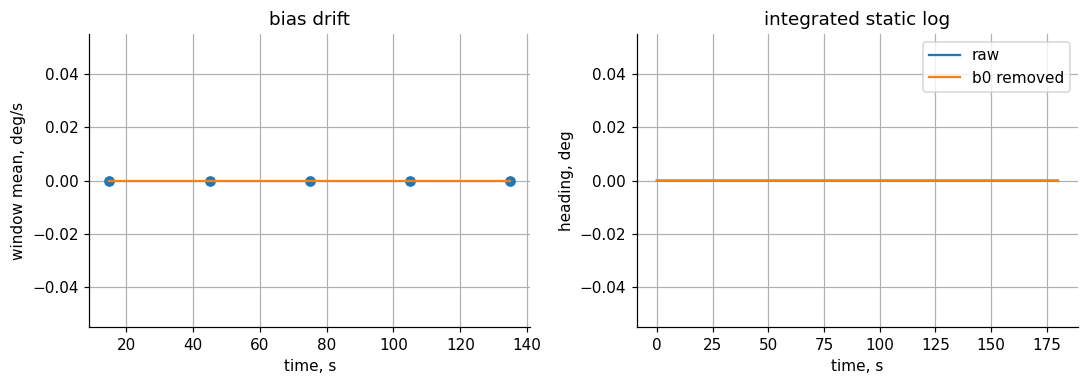

In [35]:
edges = np.arange(0, ts[-1] - ts[0] + 1e-9, 30)
win_mean = np.array([ws[(ts - ts[0] >= a) & (ts - ts[0] < a + 30)].mean() for a in edges[:-1]])
win_t = edges[:-1] + 15
slope, icpt = np.polyfit(win_t, win_mean, 1)
d_drift = slope * 60 # deg/s per min
print('window means, deg/s:', np.round(win_mean, 4))
print(f'd = {d_drift:.5f} deg/s per min')

def integrate(tt, rate): # trapezoid, real timestamps
    return np.concatenate([[0], np.cumsum((rate[1:] + rate[:-1]) / 2 * np.diff(tt))])

th_raw = integrate(ts - ts[0], ws) # (a) uncorrected
th_res = integrate(ts - ts[0], ws-b0) # (b) bias removed
rate_raw = np.polyfit(ts - ts[0], th_raw, 1)[0] * 60 # deg/min
print(f'(a) uncorrected heading drift = {rate_raw:.3f} deg/min   (b0*60 = {b0*60:.3f})')
for m in (1, 2, 3):
    i = np.searchsorted(ts-ts[0], m*60)-1
    print(f'(b) heading error after {m} min with b0 removed: {th_res[min(i, len(th_res)-1)]:.3f} deg')

fig, ax = plt.subplots(1, 2, figsize=(10,3.6))
ax[0].plot(win_t, win_mean, 'o'); 
ax[0].plot(win_t, slope*win_t + icpt); 
ax[0].set(xlabel='time, s', ylabel='window mean, deg/s', title='bias drift')
ax[1].plot(ts-ts[0], th_raw, label='raw'); 
ax[1].plot(ts-ts[0], th_res, label='b0 removed')
ax[1].set(xlabel='time, s', ylabel='heading, deg', title='integrated static log');
ax[1].legend()

plt.tight_layout(); plt.show()

## 3. Measurement range

Maximum and minimum rate in the rotation phases, and gyro rate against encoder rate (a flat top means saturation).

range: +200.0 / -200.0 deg/s
samples at the limit: 923 of 3601 in the rotation run (25.6 %)
encoder rate in those samples: up to 220 / -220 deg/s


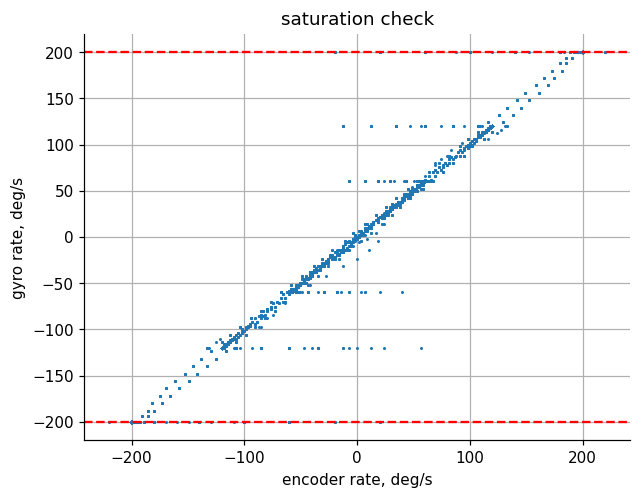

In [26]:
w_max, w_min = w[rot].max(), w[rot].min()
print(f'range: +{w_max:.1f} / {w_min:.1f} deg/s')
if has_raw:
    sat = np.abs(gz_raw) >= 32700 # raw value at the end of the 16-bit range
    print(f'raw limits: {gz_raw[rot].max():.0f} / {gz_raw[rot].min():.0f}')
else:
    sat = (np.abs(w) >= 0.99 * max(w_max, -w_min)) & rot
print(f'samples at the limit: {sat[rot].sum()} of {rot.sum()} in the rotation run ({100 * sat[rot].mean():.1f} %)')
print(f'encoder rate in those samples: up to {enc_rate[sat].max():.0f} / {enc_rate[sat].min():.0f} deg/s' if sat.any() else 'the gyro never reached its limit')

plt.plot(enc_rate[rot], w[rot], '.', ms=2)
plt.axhline(w_max, color='r', ls='--'); plt.axhline(w_min, color='r', ls='--')
plt.xlabel('encoder rate, deg/s'); plt.ylabel('gyro rate, deg/s'); plt.title('saturation check')
plt.show()

## 4. Resolution

Smallest non-zero step between distinct output values in the static log.

In [27]:
def resolution(values):
    u = np.unique(values)
    steps = np.diff(u)
    steps = steps[steps > 0]
    return steps.min() if len(steps) else np.nan

res_cal = resolution(gz_cal[static]) / 1000
print(f'distinct values in static log: {len(np.unique(gz_cal[static]))}')
print(f'resolution (from gz_cal) = {res_cal} deg/s')
if has_raw:
    # gz_cal is the raw value times a factor, written as a whole number of mdeg/s: the step in RAW units is exact
    ok_k = ~sat & rot & (np.abs(gz_raw) > 50)
    k = np.median(gz_cal[ok_k] / gz_raw[ok_k])          # mdeg/s per raw unit
    step_raw = resolution(gz_raw[static])
    res_cal = step_raw * k / 1000
    print(f'raw values at rest: {len(np.unique(gz_raw[static]))}, smallest step {step_raw} raw unit(s)')
    print(f'raw -> mdeg/s factor = {k:.4f}  ->  Delta = {step_raw} x {k/1000:.5f} = {res_cal:.5f} deg/s')
if len(np.unique(gz_cal[static])) < 3:
    print('Too few distinct values: this gyro is noise-free at rest, so the step cannot be seen there. '
          'Value from the rotation run (less reliable):', resolution(gz_cal[rot]) / 1000, 'deg/s')

distinct values in static log: 1
resolution (from gz_cal) = nan deg/s
Too few distinct values: this gyro is noise-free at rest, so the step cannot be seen there. Value from the rotation run (less reliable): 0.001 deg/s


## 5. Noise sigma

Standard deviation of the static log with b0 removed, histogram with a fitted Gaussian.

sigma = 0.0000 deg/s   R = sigma^2 = 0.000000 (deg/s)^2   at fs = 50 Hz
samples beyond 4 sigma: 0


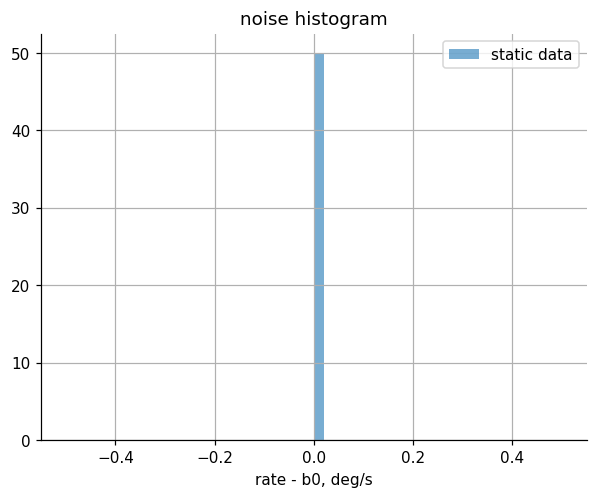

In [28]:
n_static = ws - b0
sigma = n_static.std(ddof=1)
R = sigma ** 2                                          # measurement noise variance for Lab 12 at this sample rate
print(f'sigma = {sigma:.4f} deg/s   R = sigma^2 = {R:.6f} (deg/s)^2   at fs = {fs:.0f} Hz')
outliers = np.sum(np.abs(n_static) > 4 * sigma) if sigma > 0 else 0
print(f'samples beyond 4 sigma: {outliers}')

plt.hist(n_static, bins=50, density=True, alpha=.6, label='static data')
if sigma > 0:
    xs = np.linspace(n_static.min(), n_static.max(), 200)
    plt.plot(xs, np.exp(-xs**2 / (2 * sigma**2)) / (sigma * np.sqrt(2 * np.pi)), label='Gaussian fit')
plt.xlabel('rate - b0, deg/s'); plt.legend(); plt.title('noise histogram'); plt.show()

## Step 3 of the lab: gyro angle against encoder angle

`theta_gyro = integral(w - b0)`, `theta_enc = r/W * (phi_R - phi_L)`. The offset `b0_run` comes from `calibrate_gyro` on the last seconds of the static phase, right before the run. Both angles start at 0 when the rotation starts.

The printed table shows where `e(t)` grows: at rest only the offset acts; scale-factor error shows as a steady change of `e` in every block that scales with the turned angle; saturation shows as a jump in the blocks with a large share at the limit; wheel slip would appear as steps in `e` at the hard `rect` reversals that are not at the limit.

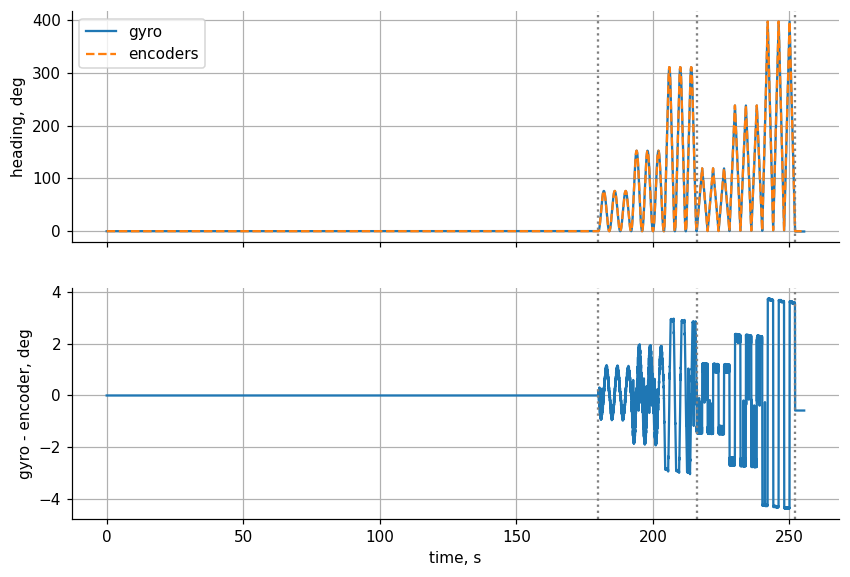

final error: -0.58 deg   (theta_gyro = -0.6, theta_enc = 0.0)
error at the end of each phase: {'static': 0.0, 'sin': -0.07, 'rect': 3.59}
final gyro angle: -0.6 deg with b0 from the last 10 s (0.000), -0.6 deg with b0 from the first 30 s (0.000)
robot standing again: gyro reads 0.000 deg/s -> offset left with b0_run: +0.000 deg/s, with the 30-s b0: +0.000 deg/s

block      change of e, deg   share at limit
sin  30 %        -0.03          0.0 %
sin  60 %         0.01          0.0 %
sin 150 %         0.05         54.0 %
rect  30 %        -0.21          0.0 %
rect  60 %         1.36          0.0 %
rect 150 %         3.84        100.0 %
static (bias only): e changes by 0.00 deg over 180 s


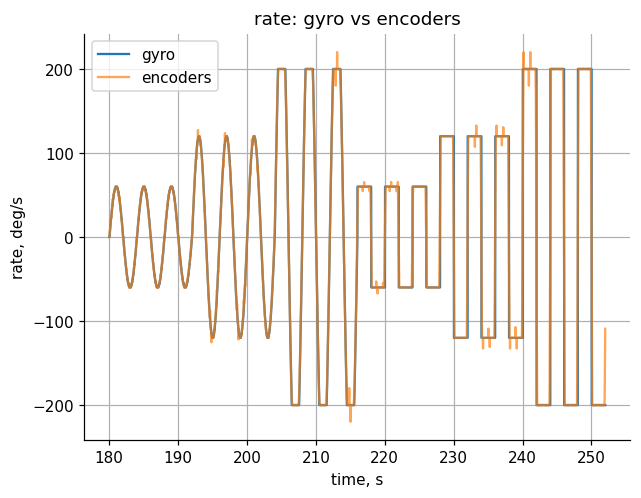

In [29]:
w_cal = w - b0_run                                  # offset from the last seconds before the run
theta_gyro = integrate(t, w_cal)
err = theta_gyro - theta_enc
i_run = np.argmax(phase > 0)                        # the rotation run starts here: heading starts at 0 there
theta_gyro = theta_gyro - theta_gyro[i_run]
theta_enc = theta_enc - theta_enc[i_run]
err = theta_gyro - theta_enc

fig, ax = plt.subplots(2, 1, figsize=(9, 6), sharex=True)
ax[0].plot(t, theta_gyro, label='gyro'); ax[0].plot(t, theta_enc, '--', label='encoders'); ax[0].set_ylabel('heading, deg'); ax[0].legend()
ax[1].plot(t, err); ax[1].set(xlabel='time, s', ylabel='gyro - encoder, deg')
for a in ax:
    for edge in (t[sin_][0], t[rect_][0], t[rest_][0]):
        a.axvline(edge, color='gray', ls=':')
plt.show()
print(f'final error: {err[-1]:.2f} deg   (theta_gyro = {theta_gyro[-1]:.1f}, theta_enc = {theta_enc[-1]:.1f})')
print('error at the end of each phase:',
      {name: round(err[m][-1], 2) for name, m in [('static', static), ('sin', sin_), ('rect', rect_)]})

# the same run with the offset of the first 30 s (what a 3-min-old calibration would give)
theta_old = integrate(t, w - b0)
theta_old -= theta_old[i_run]
print(f'final gyro angle: {theta_gyro[-1]:.1f} deg with b0 from the last {T_CAL} s ({b0_run:.3f}), {theta_old[-1]:.1f} deg with b0 from the first 30 s ({b0:.3f})')
still = rest_ & (t > t[-1] - 2)
if still.any():
    print(f'robot standing again: gyro reads {w[still].mean():.3f} deg/s -> offset left with b0_run: {w[still].mean() - b0_run:+.3f} deg/s, with the 30-s b0: {w[still].mean() - b0:+.3f} deg/s')
if SLIP_DEG is not None:
    print(f'floor-mark slip angle: {SLIP_DEG} deg (counter-clockwise positive) vs encoders {theta_enc[-1]:.1f} deg, gyro {theta_gyro[-1]:.1f} deg')

# where does e(t) grow? change of e in every 12 s block (one amplitude step), and how much of it is at the gyro limit
print('\nblock      change of e, deg   share at limit')
for ph, name in [(1, 'sin'), (2, 'rect')]:
    t_ph = t[phase == ph][0]
    for j, A in enumerate([30, 60, 150]):
        m = (phase == ph) & (t - t_ph >= 12 * j) & (t - t_ph < 12 * (j + 1))
        if m.sum() > 1:
            print(f'{name} {A:3d} %   {err[m][-1] - err[m][0]:10.2f}   {100 * sat[m].mean():10.1f} %')
print(f'static (bias only): e changes by {err[static][-1] - err[static][0]:.2f} deg over {ts[-1] - ts[0]:.0f} s')

plt.plot(t[rot], w[rot], label='gyro'); plt.plot(t[rot], enc_rate[rot], label='encoders', alpha=.7)
plt.xlabel('time, s'); plt.ylabel('rate, deg/s'); plt.legend(); plt.title('rate: gyro vs encoders'); plt.show()

## 6. Scale factor s, sign, raw -> deg/s

1. **Sign:** computed when the log is loaded. If the gyro reports positive for CW, it is multiplied by -1 so that both angles use the same convention.
2. **Raw -> deg/s:** slope of `gz_cal` against `gz_raw` (only with the JS log).
3. **Scale-factor error:** slope of `d(theta_gyro)` against `d(theta_enc)` over 0.1 s steps, CW and CCW separately. Slope = 1 + s.
   Steps from saturated moments are skipped (they would bend the line).

sign test (see load cell): the gyro reports positive for CW; correlation -0.989
no gz_raw in this log (diagram program). Run gyro_real.js on the robot for the raw -> deg/s factor.
s (CCW) = -0.42 %    s (CW) = -0.48 %
  sin, A =  30 %: s =  -0.19 %
  sin, A =  60 %: s =  -0.27 %
  sin, A = 150 %: s =  -0.66 %
  rect, A =  30 %: s =  -0.99 %
  rect, A =  60 %: s =  -0.41 %


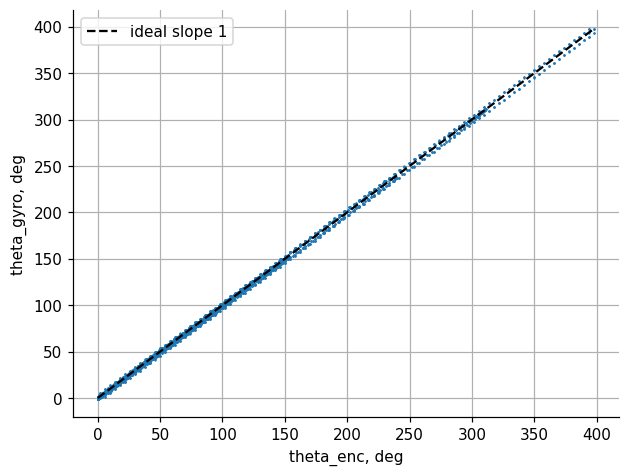

In [30]:
print(f'sign test (see load cell): the gyro reports positive for {direction}; correlation {corr:.3f}')

if has_raw:
    # k = mdeg/s per raw unit, from section 4. Check it: how many rows have gz_cal = k * gz_raw exactly?
    same = np.abs(gz_cal[~sat] - k * gz_raw[~sat]) < 1
    print(f'raw -> deg/s: {k/1000:.5f} deg/s per raw unit; gz_cal = k * gz_raw in {same.sum()} of {len(same)} rows')
    plt.plot(gz_raw[rot], gz_cal[rot], '.', ms=2); plt.xlabel('gz_raw'); plt.ylabel('gz_cal, mdeg/s'); plt.title('raw -> deg/s'); plt.show()
else:
    k = np.nan
    print('no gz_raw in this log (diagram program). Run gyro_real.js on the robot for the raw -> deg/s factor.')

step = max(2, int(0.1 * fs))
dg = (theta_gyro[step:] - theta_gyro[:-step])
de = (theta_enc[step:] - theta_enc[:-step])
sat_near = np.convolve(sat, np.ones(2 * step + 1), mode='same') > 0      # a step touching a saturated sample is skipped
ok = ~sat_near[:-step] & ~sat_near[step:] & rot[:-step]
def scale_error(mask):
    slope = np.sum(dg[mask] * de[mask]) / np.sum(de[mask] ** 2)          # least squares through the origin
    return (slope - 1) * 100
s_ccw = scale_error(ok & (de > 1)); s_cw = scale_error(ok & (de < -1))
print(f's (CCW) = {s_ccw:.2f} %    s (CW) = {s_cw:.2f} %')
# theta_enc is proportional to r, so 1 + s is proportional to 1/r: how much does s move if my r is a bit off?
s_mid = (s_ccw + s_cw) / 2
for r_alt in ((0.0375, 0.040, 0.042, 0.045) if RUN == 'real' else ()):
    print(f'  if r were {r_alt*100:.2f} cm instead of {r*100:.2f} cm: s = {((1 + s_mid / 100) * r / r_alt - 1) * 100:+.1f} %')

# does s depend on the amplitude? (12 s per amplitude step in both sin and rect)
tt = t[:-step]
for name, ph in [('sin', 1), ('rect', 2)]:
    t_start = t[phase == ph][0]
    for j, A in enumerate([30, 60, 150]):
        m = ok & (phase[:-step] == ph) & (tt - t_start >= 12 * j) & (tt - t_start < 12 * (j + 1)) & (np.abs(de) > 0.5)
        if m.sum() > 10:
            print(f'  {name}, A = {A:3d} %: s = {scale_error(m):6.2f} %')

plt.plot(theta_enc, theta_gyro, '.', ms=1); lim = [theta_enc.min(), theta_enc.max()]
plt.plot(lim, lim, 'k--', label='ideal slope 1'); plt.xlabel('theta_enc, deg'); plt.ylabel('theta_gyro, deg'); plt.legend(); plt.show()

## Simulated gyro

`gyro_sim(omega_true, t)` implements
`w_meas = Q_delta( sat_wmax( (1+s) * w_true + b0 + d*t + noise ) )`.
It is fed the rotation rate that the encoders measured and overlaid on the real log.

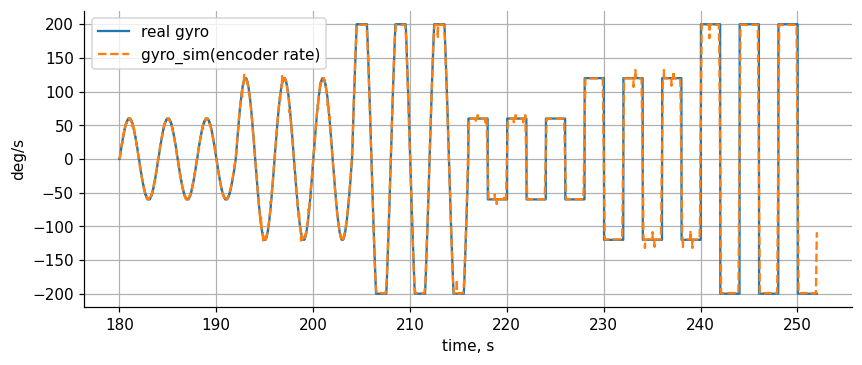

rms difference in rotation: 18.59 deg/s


In [31]:
s_mean = (s_ccw + s_cw) / 200            # average scale error as a fraction
res_use = res_cal if np.isfinite(res_cal) else 0.0

def gyro_sim(omega_true, t, b0=b0, d=d_drift / 60, w_max=max(w_max, -w_min), s=s_mean, sigma=sigma, delta=res_use, seed=0):
    rng = np.random.default_rng(seed)
    x = (1 + s) * omega_true + b0 + d * t + rng.normal(0, sigma, len(t))
    x = np.clip(x, -w_max, w_max)
    if delta > 0:
        x = np.round(x / delta) * delta
    return x

sim_out = gyro_sim(enc_rate, t)
plt.figure(figsize=(9, 3.5))
plt.plot(t[rot], w[rot], label='real gyro'); plt.plot(t[rot], sim_out[rot], '--', label='gyro_sim(encoder rate)')
plt.xlabel('time, s'); plt.ylabel('deg/s'); plt.legend(); plt.show()
print(f'rms difference in rotation: {np.sqrt(np.mean((sim_out[rot] - w[rot])**2)):.2f} deg/s')

## Parameter table

In [32]:
import pandas as pd
table = pd.DataFrame([
    ['Offset (bias)',              'b0',            b0,                   'deg/s',      f'static mean, T = 30 s (own method: {b0_own:.4f} first {T_CAL} s, {b0_run:.4f} last {T_CAL} s)'],
    ['Bias drift',                 'd',             d_drift,              'deg/s/min',  '30-s window means'],
    ['Heading drift, uncorrected', '',              rate_raw,             'deg/min',    'slope of theta(t)'],
    ['Measurement range',          '+wmax / -wmax', f'{w_max:.0f} / {w_min:.0f}', 'deg/s', 'saturation test'],
    ['Resolution',                 'Delta',         res_cal,              'deg/s',      'quantisation step'],
    ['Noise std',                  'sigma',         sigma,                'deg/s',      'static, 3 min'],
    ['Raw -> deg/s factor',        '',              k / 1000 if has_raw else 'n/a', 'deg/s per unit', 'gz_cal vs gz_raw'],
    ['Scale-factor error CCW / CW','s',             f'{s_ccw:.2f} / {s_cw:.2f}', '%',  'gyro vs encoder angle'],
    ['Positive rotation direction','',              direction, '-',          'sign check'],
], columns=['Parameter', 'Symbol', 'Value', 'Unit', 'Method'])
table

,Parameter,Symbol,Value,Unit,Method
0,Offset (bias),b0,0.0,deg/s,"static mean, T = 30 s (own method: 0.0000 firs..."
1,Bias drift,d,0.0,deg/s/min,30-s window means
2,"Heading drift, uncorrected",,0.0,deg/min,slope of theta(t)
3,Measurement range,+wmax / -wmax,200 / -200,deg/s,saturation test
4,Resolution,Delta,NaN,deg/s,quantisation step
5,Noise std,sigma,0.0,deg/s,"static, 3 min"
6,Raw -> deg/s factor,,n/a,deg/s per unit,gz_cal vs gz_raw
7,Scale-factor error CCW / CW,s,-0.42 / -0.48,%,gyro vs encoder angle
8,Positive rotation direction,,CW,-,sign check


## Which error dominates, and what the calibration leaves

Rough heading-error budget after `t` seconds of driving, using the numbers above:

- uncorrected bias: `b0 * t`
- residual bias after `calibrate_gyro` (drift only): `d * t^2 / 2`
- noise (random walk): `sigma * sqrt(dt * t)`
- scale factor: `|s| * angle turned` (angle turned scaled to the first `t` seconds of the rotation run)

In [33]:
dt = 1 / fs
turned = np.sum(np.abs(np.diff(theta_enc)))                         # total angle turned in the run, deg
s_abs = max(abs(s_ccw), abs(s_cw)) / 100
rows = []
for sec in (10, 60, 180):
    rows.append([sec, abs(b0) * sec, abs(d_drift / 60) * sec**2 / 2, sigma * np.sqrt(dt * sec), s_abs * turned * min(sec / 72, 1)])
budget = pd.DataFrame(rows, columns=['t, s', 'bias (uncorrected), deg', 'bias drift (after calibration), deg', 'noise, deg', 'scale factor, deg'])
display(budget.round(3))
print(f'calibrate_gyro needs {T_CAL} s of standing still; heading error left after 3 min static: {integrate(ts - ts[0], ws - b0_own)[-1]:.3f} deg')

,"t, s","bias (uncorrected), deg","bias drift (after calibration), deg","noise, deg","scale factor, deg"
0,10,0.0,0.0,0.0,5.182
1,60,0.0,0.0,0.0,31.090
2,180,0.0,0.0,0.0,37.308


calibrate_gyro needs 10 s of standing still; heading error left after 3 min static: -0.000 deg


## Short analysis

*(fill in after the real run, using the printed numbers: (1) which column of the budget table is largest at 10 s, 1 min, 3 min; (2) how `calibrate_gyro` works, that it needs 10 s of standing still, and that the offset drifts so it has to run right before the run; (3) the heading error it leaves after 3 min; (4) where `e(t)` grew and why (offset / scale factor / saturation / slip); (5) the floor mark against the two final angles; (6) that r and W uncertainty limits how well `s` is known, and that the sample rate is lower than the 100 Hz asked for.)*